# 01 · Data Cleaning & Exploration — Online Retail II

**Business question:** What does this online store's sales data look like, and how much of it can we trust?

**Data:** UCI *Online Retail II* — every transaction of a UK-based online gift store (many customers are wholesalers), Dec 2009 – Dec 2011, split across 2 CSV files.

**Approach:** load both files → fix data-quality problems one by one (and count what each step removes) → explore revenue, products, countries and customer behaviour.

## Importing the libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# folder for saving plots (repo: ../images, Kaggle: current folder)
IMG_DIR = '../images' if os.path.isdir('../images') else '.'

## Importing the dataset

In [2]:
# Automatically finds both CSV files under /kaggle/input (Kaggle) or ../data (local) - no manual path copying needed
files_needed = ['online_retail_09_10.csv', 'online_retail_10_11.csv']
paths = {}
for root in ['/kaggle/input', '../data', 'data']:
    for dirname, _, filenames in os.walk(root):
        for filename in filenames:
            if filename in files_needed and filename not in paths:
                paths[filename] = os.path.join(dirname, filename)

if len(paths) < 2:
    print("CSV files not found - attach the 'UCI Online Retail II' dataset under Input (Kaggle) or put them in ../data")
else:
    for f in files_needed:
        print("Found it at:", paths[f])
    # the files start with a hidden BOM character, so 'utf-8-sig' keeps the first column name clean
    dataset = pd.concat([pd.read_csv(paths[f], encoding='utf-8-sig') for f in files_needed], ignore_index=True)
    print(dataset.shape)

Found it at: ../data/online_retail_09_10.csv
Found it at: ../data/online_retail_10_11.csv


(1067371, 8)


## Understanding the data

In [3]:
dataset.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


In [4]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   InvoiceNo    1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   UnitPrice    1067371 non-null  float64
 6   CustomerID   824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


**Columns:** `InvoiceNo` (starts with **C** = cancelled), `StockCode` (product code), `Description`, `Quantity`, `InvoiceDate`, `UnitPrice` (£), `CustomerID`, `Country`.

## Checking missing values

In [5]:
print(dataset.isnull().sum())

InvoiceNo           0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     243007
Country             0
dtype: int64


`CustomerID` is missing for ~243k rows (guest checkouts). We can't segment or track customers without an ID, so those rows are dropped for customer analysis. `Description` blanks disappear with them.

## Cleaning the data step by step
Each step is recorded so we can show exactly how many rows were removed and why.

In [6]:
steps = [('Raw data (2 files combined)', len(dataset))]

# 1. Exact duplicates (the two files overlap for 1-9 Dec 2010, and some rows are repeated)
dataset = dataset.drop_duplicates()
steps.append(('Remove duplicate rows', len(dataset)))

# 2. Fix data types
dataset['InvoiceNo'] = dataset['InvoiceNo'].astype(str)
dataset['StockCode'] = dataset['StockCode'].astype(str)
dataset['InvoiceDate'] = pd.to_datetime(dataset['InvoiceDate'], format='%m/%d/%Y %H:%M')

# 3. Cancelled orders (invoice number starts with 'C')
dataset = dataset[~dataset['InvoiceNo'].str.startswith('C')]
steps.append(('Remove cancelled invoices', len(dataset)))

# 4. Returns / adjustments (zero or negative quantity or price)
dataset = dataset[(dataset['Quantity'] > 0) & (dataset['UnitPrice'] > 0)]
steps.append(('Remove quantity <= 0 or price <= 0', len(dataset)))

# 5. Rows without a customer
dataset = dataset.dropna(subset=['CustomerID'])
steps.append(('Remove rows without CustomerID', len(dataset)))

# 6. Non-product codes: postage (POST), manual (M), bank charges, tests...
dataset = dataset[dataset['StockCode'].str.match(r'^\d')]
steps.append(('Remove non-product stock codes', len(dataset)))

dataset['CustomerID'] = dataset['CustomerID'].astype(int)
dataset['Description'] = dataset['Description'].str.strip()   # some product names have stray leading/trailing spaces
dataset['Revenue'] = dataset['Quantity'] * dataset['UnitPrice']

cleaning_summary = pd.DataFrame(steps, columns=['Step', 'Rows left'])
cleaning_summary['Rows removed'] = (-cleaning_summary['Rows left'].diff()).fillna(0).astype(int)
cleaning_summary

,Step,Rows left,Rows removed
0,Raw data (2 files combined),1067371,0
1,Remove duplicate rows,1033036,34335
2,Remove cancelled invoices,1013932,19104
3,Remove quantity <= 0 or price <= 0,1007913,6019
4,Remove rows without CustomerID,779425,228488
5,Remove non-product stock codes,776577,2848


In [7]:
print("Clean rows      :", len(dataset))
print("Customers       :", dataset['CustomerID'].nunique())
print("Invoices        :", dataset['InvoiceNo'].nunique())
print("Products        :", dataset['StockCode'].nunique())
print("Countries       :", dataset['Country'].nunique())
print("Date range      :", dataset['InvoiceDate'].min().date(), "to", dataset['InvoiceDate'].max().date())
print("Total revenue   : £{:,.0f}".format(dataset['Revenue'].sum()))

Clean rows      : 776577
Customers       : 5852
Invoices        : 36594
Products        : 4619
Countries       : 41
Date range      : 2009-12-01 to 2011-12-09
Total revenue   : £17,068,568


## Exploratory Data Analysis

### Monthly revenue

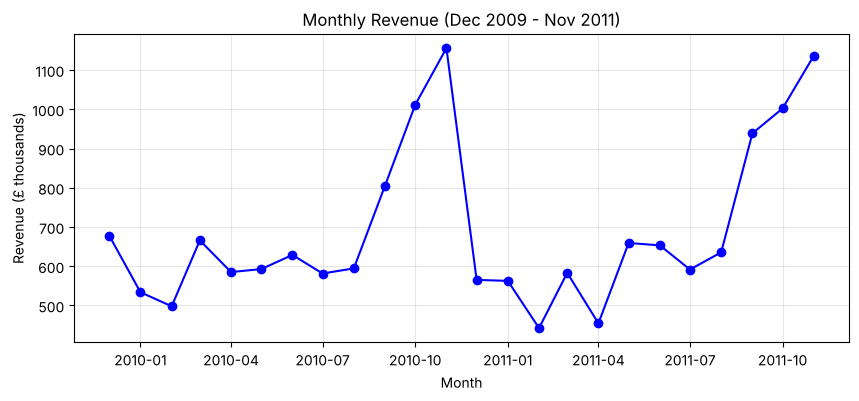

In [8]:
monthly = dataset.set_index('InvoiceDate')['Revenue'].resample('MS').sum()
monthly = monthly[monthly.index < '2011-12-01']   # Dec 2011 has only 9 days of data, so leave it out

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values / 1000, marker='o', color='blue')
plt.title('Monthly Revenue (Dec 2009 - Nov 2011)')
plt.xlabel('Month')
plt.ylabel('Revenue (£ thousands)')
plt.grid(alpha=0.3)
plt.savefig(f'{IMG_DIR}/01_monthly_revenue.png', dpi=120, bbox_inches='tight')
plt.show()

In [9]:
print("Best month :", monthly.idxmax().strftime('%b %Y'), "- £{:,.0f}".format(monthly.max()))
print("Worst month:", monthly.idxmin().strftime('%b %Y'), "- £{:,.0f}".format(monthly.min()))

Best month : Nov 2010 - £1,155,978
Worst month: Feb 2011 - £442,294


### Top 10 products by revenue

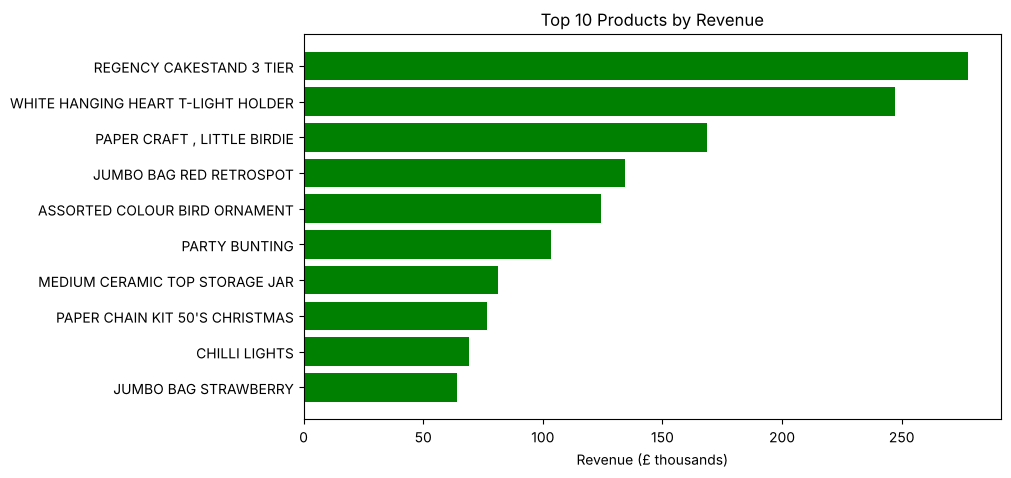

In [10]:
top_products = dataset.groupby('Description')['Revenue'].sum().nlargest(10)

plt.figure(figsize=(9, 5))
plt.barh(top_products.index[::-1], top_products.values[::-1] / 1000, color='green')
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£ thousands)')
plt.savefig(f'{IMG_DIR}/01_top_products.png', dpi=120, bbox_inches='tight')
plt.show()

### Revenue by country

In [11]:
country_revenue = dataset.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
country_share = (country_revenue / country_revenue.sum() * 100).round(1)
print(country_share.head(10))

Country
United Kingdom    83.7
EIRE               3.4
Netherlands        3.2
Germany            2.2
France             1.8
Australia          1.0
Spain              0.6
Switzerland        0.5
Sweden             0.5
Denmark            0.4
Name: Revenue, dtype: float64


### How often do customers come back?

Customers who ordered only once: 27.6 %
Median orders per customer     : 3.0


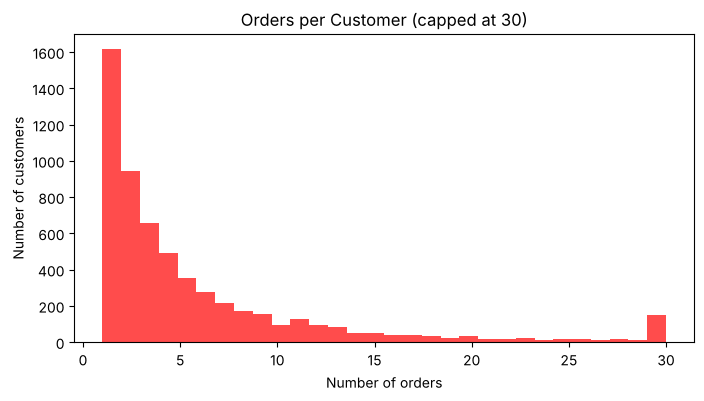

In [12]:
orders_per_customer = dataset.groupby('CustomerID')['InvoiceNo'].nunique()
one_time = (orders_per_customer == 1).mean() * 100
print("Customers who ordered only once: {:.1f} %".format(one_time))
print("Median orders per customer     :", orders_per_customer.median())

plt.figure(figsize=(8, 4))
plt.hist(orders_per_customer.clip(upper=30), bins=30, color='red', alpha=0.7)
plt.title('Orders per Customer (capped at 30)')
plt.xlabel('Number of orders')
plt.ylabel('Number of customers')
plt.savefig(f'{IMG_DIR}/01_orders_per_customer.png', dpi=120, bbox_inches='tight')
plt.show()

### Revenue concentration (Pareto check)

In [13]:
customer_revenue = dataset.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False)
top_20_pct = int(len(customer_revenue) * 0.2)
share_top20 = customer_revenue.iloc[:top_20_pct].sum() / customer_revenue.sum() * 100
print("Top 20% of customers bring {:.1f} % of revenue".format(share_top20))

Top 20% of customers bring 77.2 % of revenue


## Summary

- The cleaning table above shows exactly what was removed and why — cancelled orders, returns, guest checkouts and non-product codes.
- Sales are **seasonal**: revenue climbs every autumn and peaks before Christmas.
- Revenue is **concentrated**: a small group of customers brings most of it (Pareto check above).
- A large share of customers buy only once — the reason segmentation (notebook 02) and churn prediction (notebook 04) matter.

**Next:** 02 — RFM customer segmentation with K-Means.